In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/drive/MyDrive/dataset_project/project_dataset.csv')
df

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
0,74901,Employed,582,6365,12,No
1,55852,Employed,635,14687,48,Yes
2,79430,Employed,570,15180,24,No
3,105690,Employed,619,19726,24,Yes
4,52975,Self-Employed,460,1331,12,No
...,...,...,...,...,...,...
1995,92104,Employed,652,16714,36,Yes
1996,59204,Employed,442,26526,48,No
1997,33543,Employed,617,2825,12,No
1998,55107,Employed,814,19679,60,Yes


In [5]:
df.head()

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
0,74901,Employed,582,6365,12,No
1,55852,Employed,635,14687,48,Yes
2,79430,Employed,570,15180,24,No
3,105690,Employed,619,19726,24,Yes
4,52975,Self-Employed,460,1331,12,No


In [6]:
df.tail()

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
1995,92104,Employed,652,16714,36,Yes
1996,59204,Employed,442,26526,48,No
1997,33543,Employed,617,2825,12,No
1998,55107,Employed,814,19679,60,Yes
1999,37652,Employed,686,3297,48,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Income             2000 non-null   int64 
 1   Employment_Status  2000 non-null   object
 2   Credit_Score       2000 non-null   int64 
 3   Loan_Amount        2000 non-null   int64 
 4   Repayment_Period   2000 non-null   int64 
 5   Eligible           2000 non-null   object
dtypes: int64(4), object(2)
memory usage: 93.9+ KB


In [7]:
df.describe(include="all")

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
count,2000.000000,2000,2000.000000,2000.000000,2000.00000,2000
unique,NaN,3,NaN,NaN,NaN,2
top,NaN,Employed,NaN,NaN,NaN,Yes
freq,NaN,1396,NaN,NaN,NaN,1077
mean,62425.080000,NaN,648.058000,14959.283500,42.01800,NaN
std,27632.380078,NaN,98.544407,9174.451151,20.57385,NaN
min,20000.000000,NaN,348.000000,1000.000000,12.00000,NaN
25%,41319.750000,NaN,579.000000,8131.250000,24.00000,NaN
50%,61340.500000,NaN,649.500000,14697.000000,48.00000,NaN
75%,80488.750000,NaN,716.000000,21288.000000,60.00000,NaN


preprocessing

In [8]:
df.isnull().sum()

,0
Income,0
Employment_Status,0
Credit_Score,0
Loan_Amount,0
Repayment_Period,0
Eligible,0


there is no null values

In [9]:
df.isna()

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
1995,False,False,False,False,False,False
1996,False,False,False,False,False,False
1997,False,False,False,False,False,False
1998,False,False,False,False,False,False


In [13]:
df2=df.copy()

In [14]:
df2.duplicated().sum()

np.int64(0)

boxplotting

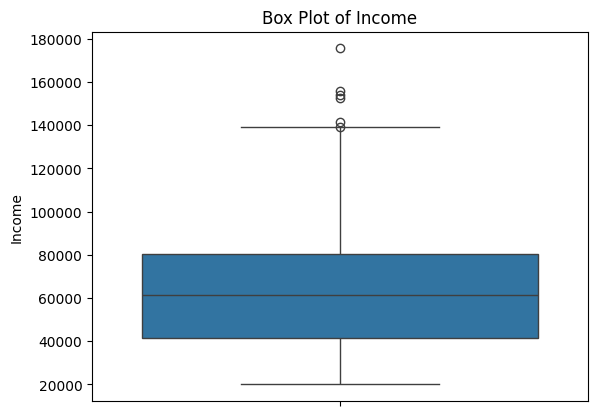

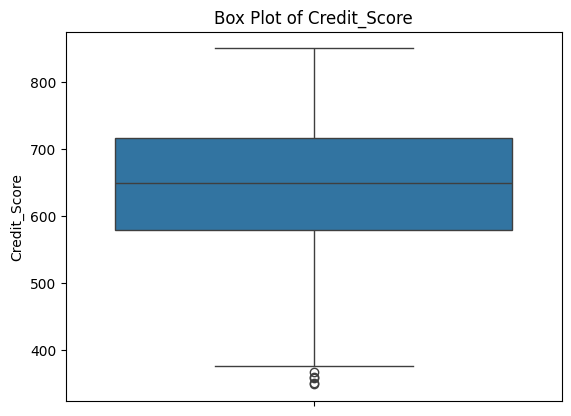

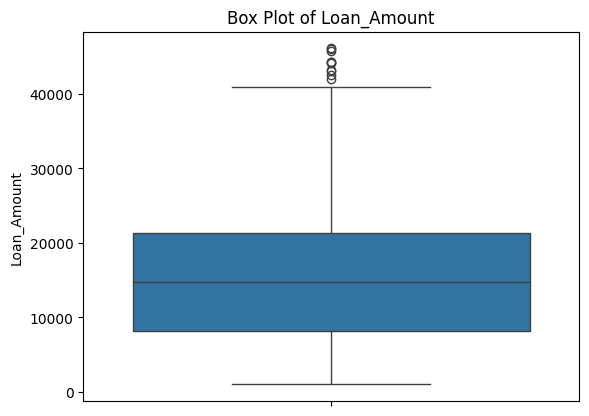

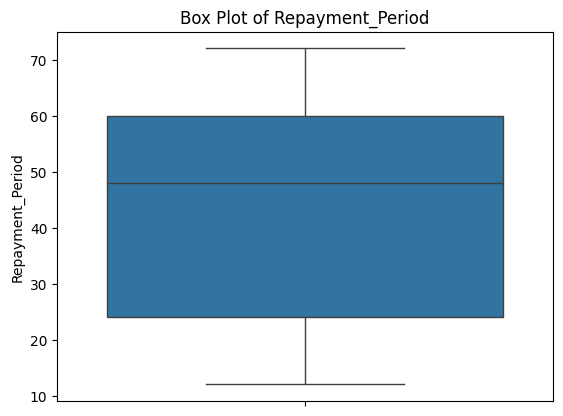

In [15]:
numerical_features = ['Income','Credit_Score','Loan_Amount','Repayment_Period']

for feature in numerical_features:
    sns.boxplot(df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [16]:
#Decision: Remove Outliers from all numerical features
for feature in numerical_features:
    q1, q3 = np.percentile(df[feature], [25, 75])
    iqr = q3 - q1
    minimum = q1 - 1.5 * iqr
    maximum = q3 + 1.5 * iqr
    df = df[(df[feature] >= minimum) & (df[feature] <= maximum)]
    print(f"Outliers removed from {feature}")
df


Outliers removed from Income
Outliers removed from Credit_Score
Outliers removed from Loan_Amount
Outliers removed from Repayment_Period


,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
0,74901,Employed,582,6365,12,No
1,55852,Employed,635,14687,48,Yes
2,79430,Employed,570,15180,24,No
3,105690,Employed,619,19726,24,Yes
4,52975,Self-Employed,460,1331,12,No
...,...,...,...,...,...,...
1995,92104,Employed,652,16714,36,Yes
1996,59204,Employed,442,26526,48,No
1997,33543,Employed,617,2825,12,No
1998,55107,Employed,814,19679,60,Yes


In [17]:
#Label Encode Categorical Features
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Employment_Status'] = le.fit_transform(df['Employment_Status'])
df['Eligible'] = le.fit_transform(df['Eligible'])
df

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
0,74901,0,582,6365,12,0
1,55852,0,635,14687,48,1
2,79430,0,570,15180,24,0
3,105690,0,619,19726,24,1
4,52975,1,460,1331,12,0
...,...,...,...,...,...,...
1995,92104,0,652,16714,36,1
1996,59204,0,442,26526,48,0
1997,33543,0,617,2825,12,0
1998,55107,0,814,19679,60,1


In [18]:
  #Feature Scaling- Numerical Only - MinMax Scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df[numerical_features] = scaler.fit_transform(df[numerical_features])
df

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period,Eligible
0,0.461465,0,0.435789,0.134532,0.0,0
1,0.301351,0,0.547368,0.343213,0.6,1
2,0.499533,0,0.410526,0.355576,0.2,0
3,0.720260,0,0.513684,0.469570,0.2,1
4,0.277168,1,0.178947,0.008300,0.0,0
...,...,...,...,...,...,...
1995,0.606064,0,0.583158,0.394042,0.4,1
1996,0.329526,0,0.141053,0.640086,0.6,0
1997,0.113834,0,0.509474,0.045763,0.0,0
1998,0.295089,0,0.924211,0.468392,0.8,1


In [19]:
# Dataset Splitting for Training and testing
from sklearn.model_selection import train_test_split
X = df.drop('Eligible', axis=1)
y = df['Eligible']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state = 42)

In [20]:
# df size: 8494x14
#X size : 8494x13
#y size: 8494x1
#X_train = 6795x13
#Y_train = 6795x1
#X_test =1699x13
#y_test = 1699x1

In [21]:
print("Shape of X_train: ", X_train.shape)
print("Shape of X_test: ", X_test.shape)
print("Shape of y_train: ", y_train.shape)
print("Shape of y_test: ", y_test.shape)

Shape of X_train:  (1583, 5)
Shape of X_test:  (396, 5)
Shape of y_train:  (1583,)
Shape of y_test:  (396,)


In [22]:
# Model Selection Training - Logistic Regression
from sklearn.linear_model import LogisticRegression  #class  import
lr = LogisticRegression() #object / instance creation
lr.fit(X_train, y_train) # Training

LogisticRegression()

In [23]:
X_test

,Income,Employment_Status,Credit_Score,Loan_Amount,Repayment_Period
572,0.418648,1,0.515789,0.553901,0.4
101,0.230140,1,0.387368,0.155746,0.6
1063,0.000000,0,0.467368,0.014770,0.8
1695,0.825134,0,0.511579,0.482434,0.2
1520,0.644115,0,0.684211,0.163996,0.6
...,...,...,...,...,...
1743,0.629195,1,0.612632,0.000000,1.0
73,0.730758,0,0.618947,0.314702,0.4
793,0.014264,1,0.383158,0.417312,0.0
263,0.077901,0,0.351579,0.277891,0.8


In [24]:
y_test

,Eligible
572,0
101,0
1063,0
1695,1
1520,1
...,...
1743,1
73,1
793,0
263,0


In [25]:
y_pred = lr.predict(X_test) #Evaluation
y_pred

array([0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1,

In [26]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test, y_pred))

0.8333333333333334


In [27]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[145  38]
 [ 28 185]]
              precision    recall  f1-score   support

           0       0.84      0.79      0.81       183
           1       0.83      0.87      0.85       213

    accuracy                           0.83       396
   macro avg       0.83      0.83      0.83       396
weighted avg       0.83      0.83      0.83       396



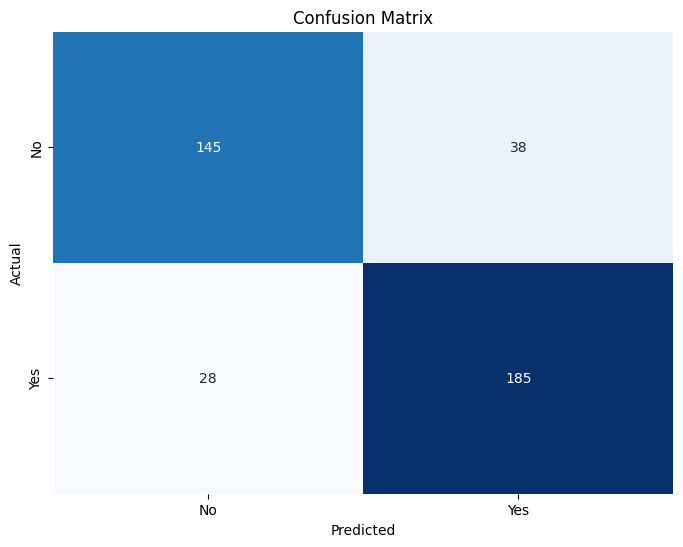

In [28]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [29]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200)
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200)

In [30]:
y_pred = rf.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.9318181818181818
[[169  14]
 [ 13 200]]
              precision    recall  f1-score   support

           0       0.93      0.92      0.93       183
           1       0.93      0.94      0.94       213

    accuracy                           0.93       396
   macro avg       0.93      0.93      0.93       396
weighted avg       0.93      0.93      0.93       396

